# Làm sạch dữ liệu giá BTCUSDT và ETHUSDT (nến 1 giờ, Binance, 2017 đến nay)

**Dữ liệu:** `crypto_1h_all.csv` (đặt cùng thư mục với notebook). File gốc chỉ đọc, mọi xử lý làm trên bản sao và xuất sang `crypto_1h_clean.csv`.
**Quy trình:** tổng quan → kiểm tra 8 nhóm lỗi → quyết định (kèm lý do) → xử lý → kiểm tra lại → xuất file.
**Nguyên tắc:** ưu tiên *gắn cờ* thay vì xoá, để bước EDA còn lọc được. Giờ trong file là UTC.

## 1. Tổng quan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)

RAW = "crypto_1h_all.csv"
raw = pd.read_csv(RAW, encoding="utf-8-sig")   # utf-8-sig: file xuất từ script có BOM dính vào tên cột đầu
df = raw.copy()

print("shape:", df.shape)
display(df.dtypes.to_frame("dtype").T)
display(df.head(3))
display(df.tail(3))
display(df.describe().T)

shape: (161660, 11)


,symbol,open_time,open,high,low,close,volume,quote_volume,trades,taker_buy_base,taker_buy_quote
dtype,str,str,float64,float64,float64,float64,float64,float64,int64,float64,float64


,symbol,open_time,open,high,low,close,volume,quote_volume,trades,taker_buy_base,taker_buy_quote
0,BTCUSDT,2017-08-17 04:00:00+00:00,4261.48,4313.62,4261.32,4308.83,47.181009,202366.138393,171,35.160503,150952.477943
1,BTCUSDT,2017-08-17 05:00:00+00:00,4308.83,4328.69,4291.37,4315.32,23.234916,100304.823567,102,21.448071,92608.279728
2,BTCUSDT,2017-08-17 06:00:00+00:00,4330.29,4345.45,4309.37,4324.35,7.229691,31282.312670,36,4.802861,20795.317224


,symbol,open_time,open,high,low,close,volume,quote_volume,trades,taker_buy_base,taker_buy_quote
161657,ETHUSDT,2026-11-11 07:00:00+00:00,2056.06,2070.35,2052.14,2069.67,6480.6902,1.336102e+07,58995,3902.1326,8.046438e+06
161658,ETHUSDT,2026-11-11 08:00:00+00:00,2069.67,2070.70,2056.62,2058.86,6710.6877,1.384379e+07,75897,3520.6981,7.266491e+06
161659,ETHUSDT,2026-11-11 09:00:00+00:00,2058.86,2062.81,2047.79,2055.63,5756.8142,1.182948e+07,58733,2273.1905,4.672494e+06


,count,mean,std,min,25%,50%,75%,max
open,161660.0,2.060869e+04,2.984380e+04,82.16,1.750125e+03,4.013970e+03,2.939594e+04,1.260112e+05
high,161660.0,2.069031e+04,2.994129e+04,82.95,1.759117e+03,4.032985e+03,2.945366e+04,1.261996e+05
low,161660.0,2.052305e+04,2.974242e+04,81.79,1.741000e+03,3.991285e+03,2.932974e+04,1.252527e+05
close,161660.0,2.060913e+04,2.984406e+04,82.17,1.750165e+03,4.014075e+03,2.939612e+04,1.260112e+05
volume,161660.0,1.190916e+04,2.069621e+04,0.00,1.197129e+03,4.445905e+03,1.429512e+04,5.088384e+05
quote_volume,161660.0,5.431901e+07,8.236767e+07,0.00,8.829511e+06,2.777263e+07,6.676120e+07,3.005634e+09
trades,161660.0,7.014024e+04,1.028868e+05,0.00,1.154600e+04,3.372750e+04,8.354025e+04,3.520247e+06
taker_buy_base,161660.0,5.933794e+03,1.029677e+04,0.00,5.973767e+02,2.177194e+03,7.134868e+03,2.395880e+05
taker_buy_quote,161660.0,2.687774e+07,4.095607e+07,0.00,4.403882e+06,1.352758e+07,3.293413e+07,1.502977e+09


**Phát hiện:** 11 cột, 2 mã (`BTCUSDT`, `ETHUSDT`). Cột `open_time` đang là chuỗi, cần chuyển sang datetime. Giá và khối lượng đã là số.

## 2. Kiểu dữ liệu (nhóm 3), cấu trúc (nhóm 7) và trùng lặp (nhóm 2)

In [2]:
df["open_time"] = pd.to_datetime(df["open_time"], utc=True)
df = df.sort_values(["symbol", "open_time"]).reset_index(drop=True)   # sắp xếp tăng dần để shift/diff đúng

NUM = ["open", "high", "low", "close", "volume", "quote_volume", "trades", "taker_buy_base", "taker_buy_quote"]
assert df[NUM].notna().all().all(), "có giá trị không phải số"

print("Trùng hoàn toàn:", df.duplicated().sum(), "| trùng khoá (symbol, open_time):", df.duplicated(["symbol", "open_time"]).sum())
display(df.groupby("symbol").agg(rows=("open_time", "size"), first=("open_time", "min"), last=("open_time", "max")))

Trùng hoàn toàn: 0 | trùng khoá (symbol, open_time): 0


,rows,first,last
symbol,,,
BTCUSDT,80830,2017-08-17 04:00:00+00:00,2026-11-11 09:00:00+00:00
ETHUSDT,80830,2017-08-17 04:00:00+00:00,2026-11-11 09:00:00+00:00


**Phát hiện:** không có dòng trùng, không có giá trị không phải số. Mỗi mã có 80.688 dòng, bắt đầu 17/08/2017.
**Quyết định:** giữ nguyên toàn bộ cột (11 cột đều có ích), chỉ chuyển kiểu và sắp xếp.

## 3. Toàn vẹn chuỗi thời gian (nhóm 8): có đủ từng giờ không?

In [3]:
df["gap_hours"] = df.groupby("symbol")["open_time"].diff().dt.total_seconds() / 3600

gaps = df[df["gap_hours"] > 1].copy()
gaps["missing_hours"] = (gaps["gap_hours"] - 1).astype(int)
gaps["gap_start"] = gaps["open_time"] - pd.to_timedelta(gaps["missing_hours"], unit="h")
gaps["gap_end"] = gaps["open_time"] - pd.Timedelta(hours=1)

summary = gaps.groupby("symbol").agg(gap_runs=("missing_hours", "size"), missing_hours=("missing_hours", "sum"))
summary["expected_rows"] = df.groupby("symbol")["open_time"].agg(lambda s: int((s.max() - s.min()) / pd.Timedelta(hours=1)) + 1)
summary["pct_missing"] = (summary["missing_hours"] / summary["expected_rows"] * 100).round(2)
display(summary)

btc = gaps[gaps.symbol == "BTCUSDT"][["gap_start", "gap_end", "missing_hours"]].reset_index(drop=True)
eth = gaps[gaps.symbol == "ETHUSDT"][["gap_start", "gap_end", "missing_hours"]].reset_index(drop=True)
print("BTC và ETH thiếu đúng cùng các khung giờ:", btc.equals(eth))
print("5 khoảng thiếu dài nhất:")
display(btc.nlargest(5, "missing_hours"))

,gap_runs,missing_hours,expected_rows,pct_missing
symbol,,,,
BTCUSDT,28,128,80958,0.16
ETHUSDT,28,128,80958,0.16


BTC và ETH thiếu đúng cùng các khung giờ: True
5 khoảng thiếu dài nhất:


,gap_start,gap_end,missing_hours
2,2018-02-08 01:00:00+00:00,2018-02-09 09:00:00+00:00,33
3,2018-06-26 02:00:00+00:00,2018-06-26 11:00:00+00:00,10
9,2019-05-15 03:00:00+00:00,2019-05-15 12:00:00+00:00,10
10,2019-08-15 02:00:00+00:00,2019-08-15 09:00:00+00:00,8
5,2018-07-04 01:00:00+00:00,2018-07-04 07:00:00+00:00,7


**Phát hiện:** mỗi mã thiếu 128 giờ (khoảng 0,16%), gom thành 28 khoảng. Hai mã thiếu **cùng** các khung giờ, nên đây là lúc sàn bảo trì hoặc ngừng giao dịch (dài nhất khoảng 33 giờ ngày 08-09/02/2018), không phải lỗi tải dữ liệu.
**Quyết định:** **không điền** giờ thiếu. Điền giá cho các giờ sàn không hoạt động là bịa dữ liệu. Gắn cờ `gap_before` cho nến ngay sau mỗi khoảng thiếu, và đặt `ret_1h` = NaN ở các dòng đó để `diff/rolling/shift` không tính nhầm xuyên qua khoảng trống.

## 4. Giá trị thiếu và số 0 (nhóm 1)

In [4]:
display(df[NUM].isna().sum().to_frame("NaN").T)
display((df[NUM] == 0).sum().to_frame("so_0").T)

z = df[df["volume"] == 0]
print("Số nến volume = 0:", len(z), "| trong đó trades = 0:", ((df["volume"] == 0) & (df["trades"] == 0)).sum())
display(z[["symbol", "open_time", "open", "high", "low", "close", "volume", "trades"]])

print("taker_buy_base = 0 nhưng volume > 0:")
display(df[(df["taker_buy_base"] == 0) & (df["volume"] > 0)][["symbol", "open_time", "volume", "trades", "taker_buy_base"]])

,open,high,low,close,volume,quote_volume,trades,taker_buy_base,taker_buy_quote
NaN,0,0,0,0,0,0,0,0,0


,open,high,low,close,volume,quote_volume,trades,taker_buy_base,taker_buy_quote
so_0,0,0,0,0,10,10,10,11,11


Số nến volume = 0: 10 | trong đó trades = 0: 10


,symbol,open_time,open,high,low,close,volume,trades
492,BTCUSDT,2017-09-06 16:00:00+00:00,4619.43,4619.43,4619.43,4619.43,0.0,0
15749,BTCUSDT,2019-06-07 21:00:00+00:00,7930.85,7930.85,7930.85,7930.85,0.0,0
30461,BTCUSDT,2021-02-11 03:00:00+00:00,44582.07,44582.07,44582.07,44582.07,0.0,0
48961,BTCUSDT,2023-03-24 12:00:00+00:00,28080.00,28080.00,28080.00,28080.00,0.0,0
80897,ETHUSDT,2017-08-19 23:00:00+00:00,290.91,290.91,290.91,290.91,0.0,0
81322,ETHUSDT,2017-09-06 16:00:00+00:00,335.00,335.00,335.00,335.00,0.0,0
81392,ETHUSDT,2017-09-09 20:00:00+00:00,298.76,298.76,298.76,298.76,0.0,0
96579,ETHUSDT,2019-06-07 21:00:00+00:00,247.70,247.70,247.70,247.70,0.0,0
111291,ETHUSDT,2021-02-11 03:00:00+00:00,1721.86,1721.86,1721.86,1721.86,0.0,0
129791,ETHUSDT,2023-03-24 12:00:00+00:00,1789.52,1789.52,1789.52,1789.52,0.0,0


taker_buy_base = 0 nhưng volume > 0:


,symbol,open_time,volume,trades,taker_buy_base
80902,ETHUSDT,2017-08-20 04:00:00+00:00,6.65904,33,0.0


**Phát hiện:** không có NaN. Có 10 nến `volume = 0` (đều có `trades = 0`), tất cả là nến phẳng (open = high = low = close), thuộc về những giờ không có giao dịch, nhiều dòng nằm sát khoảng bảo trì ở mục 3. Một nến ETH (20/08/2017) có `taker_buy_base = 0` nhưng vẫn có giao dịch, hợp lý vì toàn bộ lệnh khớp là bên bán chủ động.
**Quyết định:** giữ nguyên các số 0 này (chỉ 10 trên 161.376 dòng, và `trades = 0` cho thấy đúng là giờ không có giao dịch), gắn cờ `is_flat_candle` để EDA loại ra khi tính trung bình khối lượng nếu cần.

## 5. Lỗi logic và ràng buộc (nhóm 5)

In [5]:
checks = {
    "giá <= 0": (df[["open", "high", "low", "close"]] <= 0).any(axis=1).sum(),
    "high < low": (df["high"] < df["low"]).sum(),
    "high < max(open, close)": (df["high"] < df[["open", "close"]].max(axis=1)).sum(),
    "low > min(open, close)": (df["low"] > df[["open", "close"]].min(axis=1)).sum(),
    "taker_buy_base > volume": (df["taker_buy_base"] > df["volume"] + 1e-9).sum(),
    "taker_buy_quote > quote_volume": (df["taker_buy_quote"] > df["quote_volume"] + 1e-6).sum(),
}
m = df["volume"] > 0
vwap = df.loc[m, "quote_volume"] / df.loc[m, "volume"]
checks["giá bình quân (quote_volume/volume) ngoài [low, high]"] = int(((vwap < df.loc[m, "low"] * 0.999) | (vwap > df.loc[m, "high"] * 1.001)).sum())
display(pd.Series(checks, name="so_dong_vi_pham").to_frame())

flat = (df["open"] == df["high"]) & (df["high"] == df["low"]) & (df["low"] == df["close"])
print("Nến phẳng:", flat.sum(), "| có volume > 0:", (flat & (df["volume"] > 0)).sum())
display(df[flat & (df["volume"] > 0)][["symbol", "open_time", "open", "close", "volume", "trades"]])

,so_dong_vi_pham
giá <= 0,0
high < low,0
"high < max(open, close)",0
"low > min(open, close)",0
taker_buy_base > volume,0
taker_buy_quote > quote_volume,0
"giá bình quân (quote_volume/volume) ngoài [low, high]",0


Nến phẳng: 12 | có volume > 0: 2


,symbol,open_time,open,close,volume,trades
80912,ETHUSDT,2017-08-20 14:00:00+00:00,294.25,294.25,3.90000,2
81711,ETHUSDT,2017-09-23 03:00:00+00:00,263.00,263.00,10.65402,22


**Phát hiện:** các ràng buộc OHLC và khối lượng đều đạt (0 vi phạm). Có 12 nến phẳng: 10 nến không giao dịch (đã thấy ở mục 4) và 2 nến phẳng **có** giao dịch của ETH năm 2017 (chỉ 2 và 22 lệnh), đáng nghi vì thị trường mỏng.

Tiếp theo kiểm tra tính liên tục: `open` của giờ này phải gần `close` của giờ trước (thị trường chạy 24/7).

In [6]:
df["prev_close"] = df.groupby("symbol")["close"].shift()
df["gap_pct"] = (df["open"] / df["prev_close"] - 1) * 100

consec = df[df["gap_hours"] == 1]                      # chỉ so các cặp giờ liền kề
by_year = consec.groupby(consec["open_time"].dt.year).agg(
    ti_le_open_lech_hon_0_5pct=("gap_pct", lambda s: (s.abs() > 0.5).mean()),
    trades_median_moi_gio=("trades", "median"),
)
display(by_year.round(4))

print("Các cặp giờ liền kề có open lệch close trước hơn 20%:")
display(consec[consec["gap_pct"].abs() > 20][["symbol", "open_time", "prev_close", "open", "high", "low", "close", "trades", "gap_pct"]])

,ti_le_open_lech_hon_0_5pct,trades_median_moi_gio
open_time,,
2017,0.0791,407.0
2018,0.0003,6379.0
2019,0.0000,7766.5
2020,0.0000,18545.5
2021,0.0000,54434.5
2022,0.0000,42823.0
2023,0.0000,27463.5
2024,0.0000,62053.0
2025,0.0000,117396.5


Các cặp giờ liền kề có open lệch close trước hơn 20%:


,symbol,open_time,prev_close,open,high,low,close,trades,gap_pct
80950,ETHUSDT,2017-08-22 04:00:00+00:00,280.0,144.21,309.03,144.21,287.0,142,-48.496429


**Phát hiện:** năm 2017 có khoảng 8% cặp giờ liền kề mà `open` lệch `close` trước hơn 0,5%, từ 2018 trở đi gần như bằng 0. Cùng lúc đó, số lệnh trung vị mỗi giờ của năm 2017 rất thấp so với các năm sau. Nguyên nhân là **thị trường mỏng** những tháng đầu Binance, không phải lỗi nguồn. Riêng nến ETH 22/08/2017 04:00 có `open = low = 144,21` trong khi giờ trước đóng ở 280,00 (lệch khoảng -48%) trong khi `close` quay lại 287, rất giống một giao dịch đơn lẻ sai giá.
**Quyết định:**
- Gắn `is_thin_period` cho toàn bộ dữ liệu trước 01/01/2018 và **không** dùng giai đoạn này để tính ngưỡng ngoại lai (xem mục 6).
- Gắn `ohlc_suspect` cho 3 nến: 2 nến phẳng có giao dịch và nến ETH 22/08/2017 04:00. Không sửa vì không có giá đúng để thay.

## 6. Gắn cờ và ngoại lai (nhóm 4)

In [7]:
THIN_END = pd.Timestamp("2018-01-01", tz="UTC")

df["gap_before"] = df["gap_hours"] > 1
df["is_flat_candle"] = flat
df["is_thin_period"] = df["open_time"] < THIN_END
df["ohlc_suspect"] = (flat & (df["volume"] > 0)) | ((df["gap_hours"] == 1) & (df["gap_pct"].abs() > 20))

# nến cuối của mỗi mã: file được tải trong giờ đó nên chưa đóng
df["is_incomplete"] = False
df.loc[df.groupby("symbol")["open_time"].idxmax(), "is_incomplete"] = True
for s, g in df.groupby("symbol"):
    last, ref = g.iloc[-1], g.iloc[-25:-1]["volume"].median()
    print(f"{s}: nến cuối {last.open_time:%d/%m/%Y %H:%M} UTC, volume = {last.volume:,.1f} (trung vị 24 giờ trước = {ref:,.1f})")

print("Nến bị gắn ohlc_suspect:", int(df["ohlc_suspect"].sum()))
display(df[df["ohlc_suspect"]][["symbol", "open_time", "open", "high", "low", "close", "volume", "trades"]])

BTCUSDT: nến cuối 11/11/2026 09:00 UTC, volume = 447.3 (trung vị 24 giờ trước = 632.0)
ETHUSDT: nến cuối 11/11/2026 09:00 UTC, volume = 5,756.8 (trung vị 24 giờ trước = 9,142.3)
Nến bị gắn ohlc_suspect: 3


,symbol,open_time,open,high,low,close,volume,trades
80912,ETHUSDT,2017-08-20 14:00:00+00:00,294.25,294.25,294.25,294.25,3.90000,2
80950,ETHUSDT,2017-08-22 04:00:00+00:00,144.21,309.03,144.21,287.00,149.91376,142
81711,ETHUSDT,2017-09-23 03:00:00+00:00,263.00,263.00,263.00,263.00,10.65402,22


Dùng **log-return mỗi giờ** để tìm ngoại lai, không tìm trực tiếp trên giá vì giá đi từ khoảng 80 lên hơn 126.000 (IQR trên giá sẽ gắn cờ gần như cả giai đoạn gần đây). Ngưỡng IQR × 3 tính **riêng từng mã**, chỉ trên giai đoạn từ 01/01/2018 và bỏ nến chưa đóng.

In [8]:
START, K = THIN_END, 3

df["ret_1h"] = np.where(df["gap_hours"] == 1, np.log(df["close"] / df["prev_close"]), np.nan)   # NaN khi có khoảng thiếu
df["ret_outlier"] = False

thr, rows = {}, []
for s, g in df.groupby("symbol"):
    ref = g[(g["open_time"] >= START) & (~g["is_incomplete"])]["ret_1h"].dropna()
    q1, q3 = ref.quantile([0.25, 0.75])
    lo, hi = q1 - K * (q3 - q1), q3 + K * (q3 - q1)
    thr[s] = (lo, hi)
    idx = g.index[(g["open_time"] >= START) & ((g["ret_1h"] < lo) | (g["ret_1h"] > hi))]
    df.loc[idx, "ret_outlier"] = True
    before = g[(g["open_time"] < START)]["ret_1h"]
    rows.append({"symbol": s, "gio_xet": len(ref), "nguong_duoi": lo, "nguong_tren": hi,
                 "so_ngoai_lai": len(idx), "ti_le": len(idx) / len(ref),
                 "vuot_nguong_trong_2017": int(((before < lo) | (before > hi)).sum())})
res = pd.DataFrame(rows).set_index("symbol")
display(res.round(4))

,gio_xet,nguong_duoi,nguong_tren,so_ngoai_lai,ti_le,vuot_nguong_trong_2017
symbol,,,,,,
BTCUSDT,77524,-0.0168,0.0170,2576,0.0332,546
ETHUSDT,77524,-0.0230,0.0232,2186,0.0282,334


Cột `vuot_nguong_trong_2017` cho thấy vì sao phải loại giai đoạn thưa: năm 2017 chỉ có khoảng 3.300 giờ mà BTC đã có 546 giờ vượt ngưỡng (khoảng 17%) và ETH 331 giờ (khoảng 10%), trong khi từ 2018 trở đi tỉ lệ chỉ khoảng 3%. Do thị trường mỏng làm return bị méo.

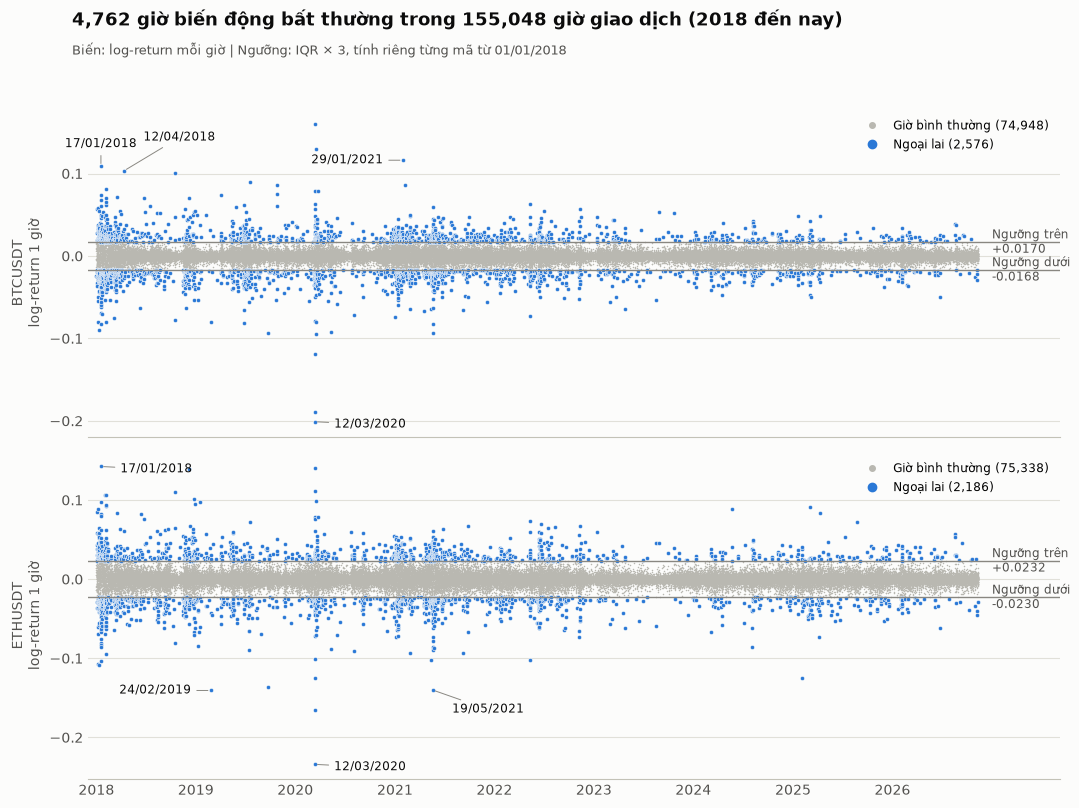

In [9]:
def pick_labels(d, n=4, min_days=45):
    # chọn n điểm lớn nhất, mỗi điểm cách nhau ít nhất min_days ngày để nhãn không chồng nhau
    picked = []
    for _, r in d.reindex(d["ret_1h"].abs().sort_values(ascending=False).index).iterrows():
        if all(abs((r.open_time - p.open_time).days) > min_days for p in picked):
            picked.append(r)
        if len(picked) == n:
            break
    return picked


LABEL_OFFSETS = {   # (dx, dy, ha) theo điểm ảnh, khoá là nhãn ngày; chỉnh tay sau khi xem ảnh, mặc định (14, -2, "left")
    "BTCUSDT": {"17/01/2018": (0, 16, "center"), "12/04/2018": (14, 24, "left"), "29/01/2021": (-14, 0, "right")},
    "ETHUSDT": {"24/02/2019": (-14, 0, "right"), "19/05/2021": (14, -14, "left")},
}
YEARS = pd.to_datetime([f"{y}-01-01" for y in range(2018, 2027)], utc=True)

fig, axes = plt.subplots(2, 1, figsize=(11, 8.2), sharex=True)
fig.patch.set_facecolor("#fcfcfb")
total_out, total_n = 0, 0
for ax, s in zip(axes, ["BTCUSDT", "ETHUSDT"]):
    g = df[(df["symbol"] == s) & (df["open_time"] >= START) & df["ret_1h"].notna() & ~df["is_incomplete"]]
    lo, hi = thr[s]
    norm, out = g[~g["ret_outlier"]], g[g["ret_outlier"]]
    total_out += len(out); total_n += len(g)
    ax.set_facecolor("#fcfcfb")
    ax.scatter(norm["open_time"], norm["ret_1h"], s=1.2, c="#b9b8b1", lw=0, rasterized=True, label=f"Giờ bình thường ({len(norm):,})")
    ax.scatter(out["open_time"], out["ret_1h"], s=9, c="#2a78d6", ec="#fcfcfb", lw=0.4, rasterized=True, label=f"Ngoại lai ({len(out):,})")
    for y in (lo, hi):
        ax.axhline(y, c="#898781", lw=1)
    xr = g["open_time"].max()
    ax.set_xlim(g["open_time"].min() - pd.Timedelta(days=30), xr + pd.Timedelta(days=300))   # chừa lề phải cho nhãn ngưỡng
    ax.annotate(f"Ngưỡng trên\n{hi:+.4f}", (xr, hi), xytext=(10, 0), textcoords="offset points", ha="left", va="center", fontsize=8.5, color="#52514e")
    ax.annotate(f"Ngưỡng dưới\n{lo:+.4f}", (xr, lo), xytext=(10, 0), textcoords="offset points", ha="left", va="center", fontsize=8.5, color="#52514e")
    for r in pick_labels(out):
        key = f"{r.open_time:%d/%m/%Y}"
        dx, dy, ha = LABEL_OFFSETS[s].get(key, (14, -2, "left"))
        ax.annotate(key, (r.open_time, r.ret_1h), xytext=(dx, dy), textcoords="offset points",
                    ha=ha, va="center", fontsize=8.5, color="#0b0b0b",
                    arrowprops=dict(arrowstyle="-", color="#898781", lw=0.7))
    ax.set_yticks([-0.2, -0.1, 0.0, 0.1])               # đặt lệch khỏi đường ngưỡng để vạch lưới không trùng
    ax.set_ylabel(f"{s}\nlog-return 1 giờ", color="#52514e")
    ax.grid(axis="y", c="#e1e0d9", lw=0.8); ax.set_axisbelow(True)
    for sp in ("top", "right", "left"):
        ax.spines[sp].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
    ax.tick_params(colors="#52514e", length=0)
    handles = [plt.Line2D([], [], marker="o", ls="", ms=4, color="#b9b8b1", label=f"Giờ bình thường ({len(norm):,})"),
               plt.Line2D([], [], marker="o", ls="", ms=6, color="#2a78d6", label=f"Ngoại lai ({len(out):,})")]
    ax.legend(handles=handles, loc="upper right", frameon=False, fontsize=8.5)
axes[1].set_xticks(YEARS)
axes[1].set_xticklabels([str(y.year) for y in YEARS])
fig.suptitle(f"{total_out:,} giờ biến động bất thường trong {total_n:,} giờ giao dịch (2018 đến nay)", x=0.07, ha="left", fontsize=13, fontweight="bold", color="#0b0b0b")
fig.text(0.07, 0.925, "Biến: log-return mỗi giờ | Ngưỡng: IQR × 3, tính riêng từng mã từ 01/01/2018", fontsize=9.5, color="#52514e")
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig("outlier_chart.png", dpi=200, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()

In [10]:
for s in ["BTCUSDT", "ETHUSDT"]:
    g = df[(df["symbol"] == s) & df["ret_outlier"]]
    top = g.reindex(g["ret_1h"].abs().sort_values(ascending=False).index).head(10)
    t = top[["open_time", "close", "ret_1h", "volume"]].copy()
    t["pct_change"] = (np.exp(t["ret_1h"]) - 1) * 100
    print(f"10 giờ biến động lớn nhất: {s}")
    display(t.round({"close": 2, "ret_1h": 4, "volume": 1, "pct_change": 2}).reset_index(drop=True))

o = df[df["ret_outlier"]]
print("Số giờ ngoại lai theo năm:")
display(o.groupby([o["open_time"].dt.year, "symbol"]).size().unstack(fill_value=0))
print("Các ngày có nhiều giờ ngoại lai nhất:")
display(o.groupby([o["open_time"].dt.date, "symbol"]).size().unstack(fill_value=0).assign(tong=lambda x: x.sum(axis=1)).nlargest(8, "tong"))

10 giờ biến động lớn nhất: BTCUSDT


,open_time,close,ret_1h,volume,pct_change
0,2020-03-12 10:00:00+00:00,6014.90,-0.2010,28792.7,-18.21
1,2020-03-12 23:00:00+00:00,4800.00,-0.1897,39952.4,-17.28
2,2020-03-13 02:00:00+00:00,4848.71,0.1603,41434.1,17.38
3,2020-03-15 21:00:00+00:00,5903.77,0.1295,22376.0,13.83
4,2020-03-13 01:00:00+00:00,4130.64,-0.1194,23916.9,-11.26
5,2021-01-29 08:00:00+00:00,36240.24,0.1161,19312.8,12.32
6,2018-01-17 16:00:00+00:00,10287.97,0.1088,4679.6,11.49
7,2018-04-12 11:00:00+00:00,7690.00,0.1033,16480.9,10.89
8,2018-10-15 06:00:00+00:00,7410.03,0.1007,17721.9,10.60
9,2020-03-15 22:00:00+00:00,5367.76,-0.0952,22974.1,-9.08


10 giờ biến động lớn nhất: ETHUSDT


,open_time,close,ret_1h,volume,pct_change
0,2020-03-12 10:00:00+00:00,132.91,-0.2341,378094.8,-20.87
1,2020-03-12 23:00:00+00:00,107.82,-0.1658,430425.1,-15.28
2,2018-01-17 16:00:00+00:00,902.75,0.1424,28199.8,15.30
3,2019-02-24 14:00:00+00:00,139.89,-0.1407,279023.5,-13.13
4,2021-05-19 12:00:00+00:00,2365.18,-0.1402,437462.4,-13.08
5,2020-03-13 02:00:00+00:00,111.12,0.1398,463034.3,15.01
6,2018-12-07 19:00:00+00:00,96.65,0.1398,123676.8,15.00
7,2019-09-24 18:00:00+00:00,165.33,-0.1359,138317.8,-12.71
8,2025-02-03 01:00:00+00:00,2491.99,-0.1249,289020.7,-11.74
9,2020-03-13 04:00:00+00:00,109.70,-0.1245,263329.4,-11.70


Số giờ ngoại lai theo năm:


symbol,BTCUSDT,ETHUSDT
open_time,,
2018,700,592
2019,295,205
2020,259,241
2021,557,481
2022,299,280
2023,97,50
2024,186,114
2025,102,148
2026,81,75


Các ngày có nhiều giờ ngoại lai nhất:


symbol,BTCUSDT,ETHUSDT,tong
open_time,,,
2018-01-16,17,18,35
2018-01-17,16,16,32
2020-03-13,18,13,31
2021-05-19,13,16,29
2018-01-08,12,15,27
2018-02-06,16,11,27
2018-01-18,13,13,26
2020-03-16,13,13,26


**Phát hiện:** các điểm lớn nhất dồn thành cụm theo thời gian (tháng 1-2/2018, 12-16/03/2020, 19/05/2021), không rải ngẫu nhiên, và đi kèm khối lượng giao dịch rất lớn. Đó là dấu hiệu của **biến cố thị trường thật**, không phải lỗi dữ liệu.
**Quyết định:** **giữ và gắn cờ** `ret_outlier`, không xoá và không winsorize. Xoá sẽ làm mất đúng những giờ quan trọng nhất của chuỗi.

## 7. Kiểm tra lại và xuất file

In [11]:
assert len(df) == len(raw), "mất hoặc thừa dòng"
assert not df.duplicated(["symbol", "open_time"]).any()
assert df.groupby("symbol")["open_time"].apply(lambda s: s.is_monotonic_increasing).all()
assert all(v == 0 for v in checks.values()), "còn vi phạm ràng buộc OHLC"
assert int(df["gap_before"].sum()) == len(gaps), "số cờ gap_before không khớp số khoảng thiếu"
assert df.loc[df["gap_before"], "ret_1h"].isna().all(), "ret_1h phải là NaN sau khoảng thiếu"
assert not df.loc[df["is_thin_period"], "ret_outlier"].any(), "giai đoạn thưa không được gắn ngoại lai"
print("Tất cả kiểm tra đạt.")

out_cols = list(raw.columns) + ["gap_before", "is_flat_candle", "is_thin_period", "ohlc_suspect", "is_incomplete", "ret_1h", "ret_outlier"]
clean = df[out_cols]
clean.to_csv("crypto_1h_clean.csv", index=False, encoding="utf-8-sig")
print("Đã lưu crypto_1h_clean.csv:", clean.shape)

tom_tat = pd.DataFrame([
    ["Khoảng thiếu giờ (sàn bảo trì)", f"{int(summary['missing_hours'].iloc[0])} giờ/mã, {len(btc)} khoảng, cả 2 mã giống nhau", "Không điền; cờ gap_before; ret_1h = NaN sau khoảng thiếu"],
    ["Nến không giao dịch (volume = 0)", f"{int((df['volume'] == 0).sum())} dòng", "Giữ nguyên; cờ is_flat_candle"],
    ["Nến phẳng có giao dịch / lệch open > 20%", f"{int(df['ohlc_suspect'].sum())} dòng", "Không sửa; cờ ohlc_suspect"],
    ["Giai đoạn thị trường mỏng", f"{int(df['is_thin_period'].sum()):,} dòng (trước 2018)", "Giữ; cờ is_thin_period; không dùng để tính ngưỡng"],
    ["Nến cuối chưa đóng", f"{int(df['is_incomplete'].sum())} dòng", "Giữ; cờ is_incomplete; bỏ khi phân tích"],
    ["Ngoại lai log-return 1 giờ", f"{int(df['ret_outlier'].sum()):,} dòng", "Giữ; cờ ret_outlier (sự kiện thị trường thật)"],
    ["Trùng lặp, NaN, vi phạm OHLC", "0", "Không cần xử lý"],
], columns=["Vấn đề", "Quy mô", "Xử lý"])
display(tom_tat)

Tất cả kiểm tra đạt.


Đã lưu crypto_1h_clean.csv: (161660, 18)


,Vấn đề,Quy mô,Xử lý
0,Khoảng thiếu giờ (sàn bảo trì),"128 giờ/mã, 28 khoảng, cả 2 mã giống nhau",Không điền; cờ gap_before; ret_1h = NaN sau kh...
1,Nến không giao dịch (volume = 0),10 dòng,Giữ nguyên; cờ is_flat_candle
2,Nến phẳng có giao dịch / lệch open > 20%,3 dòng,Không sửa; cờ ohlc_suspect
3,Giai đoạn thị trường mỏng,"6,556 dòng (trước 2018)",Giữ; cờ is_thin_period; không dùng để tính ngưỡng
4,Nến cuối chưa đóng,2 dòng,Giữ; cờ is_incomplete; bỏ khi phân tích
5,Ngoại lai log-return 1 giờ,"4,762 dòng",Giữ; cờ ret_outlier (sự kiện thị trường thật)
6,"Trùng lặp, NaN, vi phạm OHLC",0,Không cần xử lý


## 8. Lưu ý cho bước EDA

- **Giờ trong file là UTC.** Khi phân tích theo giờ Việt Nam, cộng thêm 7 giờ.
- Dùng `ret_1h` (đã là log-return) cho phân tích biến động, không dùng thẳng giá. Lọc `~is_incomplete` và cân nhắc `~is_thin_period` khi tính thống kê.
- Khi dùng `rolling`/`shift`, nhớ rằng có 28 khoảng thiếu giờ; cột `gap_before` cho biết chỗ nào.
- Hai mã có cùng khung giờ thiếu nên ghép (merge) theo `open_time` để tính tương quan BTC–ETH sẽ khớp.

## 9. Hai quyết định đã chọn

1. **Giai đoạn phân tích: giữ toàn bộ từ 2017, gắn cờ `is_thin_period` cho giai đoạn trước 2018.** Bỏ 2017 sẽ mất đợt tăng đầu tiên và năm duy nhất mà tương quan BTC–ETH còn lỏng. Thay vào đó, notebook EDA so sánh kết quả khi giữ và khi bỏ 2017, còn ngưỡng ngoại lai `ret_outlier` chỉ tính từ 2018 để không bị giai đoạn thưa kéo lệch. Nếu một báo cáo chỉ tập trung vào biến động, có thể lọc bằng `~is_thin_period`.
2. **Nến `volume = 0` (10 dòng, đều có `trades = 0`): giữ nguyên, gắn cờ `is_flat_candle`.** Đây là những giờ không có lệnh nào khớp, không phải lỗi ghi dữ liệu, và số dòng rất nhỏ so với toàn bộ nên gần như không ảnh hưởng khối lượng trung bình. Nếu cần loại hẳn khi tính trung bình khối lượng, đổi `volume` của các dòng này thành NaN.